<a href="https://colab.research.google.com/github/nmhom/MAT-422/blob/main/diabetes_logreg.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

- Feature: One measurement used as a clue, like BMI or Glucose
- Target: the answer the model tries to predict (diabetic (1) or not (0))
- X and y: X is the table of features(the clues). y is the target column (the answers)

- Imputation: filling in missing values with a reasonable guess
- Scaling: putting all features on the same scale, so a feature with big numbers (insulin, up to 846) doesn't overpower one with small numbers
- Pipeline: a recipe that chains steps so they always run in order

- Training vs test data: the model learns from training patients, then is graded on test patients it has never seen
- Data leakage: when infomation form the test patients sneaks into training, like computing the fill-in average from all patients.
- Cross-validation (10-fold): split the patients into 10 groups. Test on each group once while training on the other 9, then average the 10 scores.
- Fold: one of those 10 groups
- Stratified: every fold keeps the same mix of non-diabetic and diabetic patients
- Random seed: fixes the randomness, so you get the same results every time you run the code

- Accuracy: the percent of all patients it labeled correctly
- Precision: Of the patients it flagged as diabetic, the percent who really are. low precision means many false alarms
- Recall: of the patients who really are diabetic, the percent it caught. Low recall means many missed cases
- F1 score: one number that balances precision and recall. It's high only if both are decent
- ROC-AUC: how well the model ranks diabetic patients above non-diabetic ones.

- Logistic regression: turns the measurements into a probability of diabetes, then predicts "diabetic" if it's over 50%, it's your main model
- Decision tree: asks a series of yes/no questions to reach an answer
- SVM: draws the best possible boundary line separating the two groups
- k-NN: looks at the most similar patients and goes with what most of them have
- Naive Bayes: combines the probabilities from each feature separately to make a guess

## Section 0: Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import cross_val_score, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import VotingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from scipy import stats

## Section 1: Data exploration

This section describes the dataset before any modeling:

- **Size:** 768 patients and 9 columns (8 measurements + 1 Outcome)
- **Class balance:** 500 non-diabetic (0) and 268 diabetic (1), so about 35% of patients are diabetic
- **Missing values:** zeros in Glucose (5), BloodPressure (35), SkinThickness(227), Insulin (374), and BMI (11) are impossible values, so they are treated as missing
- **Summary statistics:** mean, standard deviation, min, and max for each column. (These include the fake zeros, so the means for Insulin and SkinThickness are pulled down.)

**Correlation heatmap.** The heatmap shows the strength and direction of the linear relationship between each pair of variables. Zeros were treated as missing before computing it.

The strongest relationships between measurements are:
1. **BMI and SkinThickness** (r = 0.68)
2. **Glucose and Insulin** (r = 0.58)
3. **Age and Pregnancies** (r = 0.54)

Heavier patients tend to have thicker skin folds, insulin rises with blood sugar, and older women have had more pregnancies.

The measurement most related to **Outcome** is **Glucose**, which suggests it will be the most important predictor.

(Rows, columns):  (768, 9)

Outcome
0    500
1    268
Name: count, dtype: int64

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  

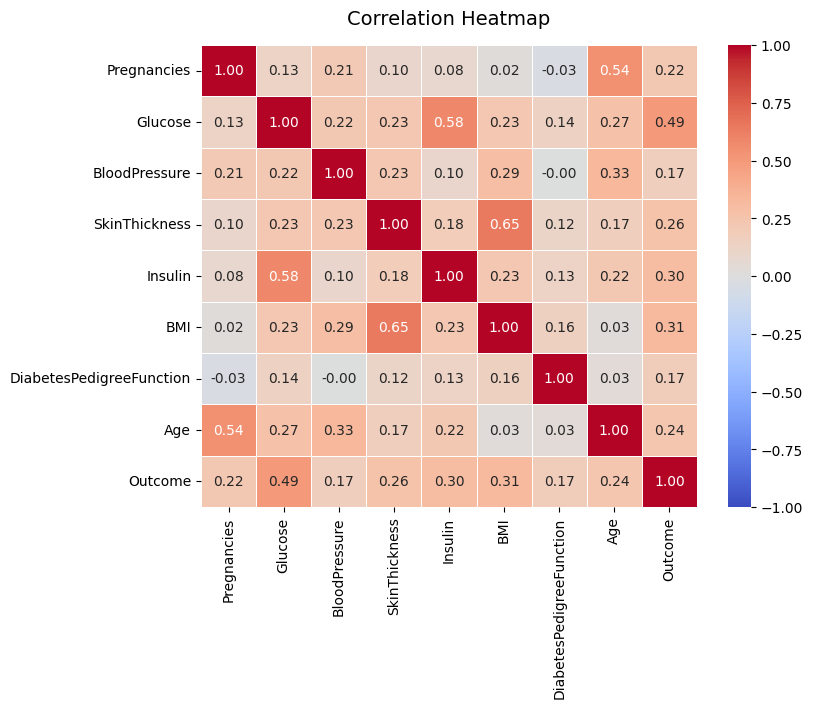

Outcome                     1.00
Glucose                     0.49
BMI                         0.31
Insulin                     0.30
SkinThickness               0.26
Age                         0.24
Pregnancies                 0.22
DiabetesPedigreeFunction    0.17
BloodPressure               0.17
Name: Outcome, dtype: float64


In [18]:
df = pd.read_csv('diabetes.csv')
print("(Rows, columns): ", df.shape)
print()
print(df["Outcome"].value_counts()) # Counts how many patients are diabetic (1) and not diabetic (0)
print()
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print((df[zero_cols] == 0).sum())  # zeros here are really missing values
print()
summary_stats = df.describe()
print(summary_stats)

df_nan = df.copy()
df_nan[zero_cols] = df_nan[zero_cols].replace(0, np.nan)
corr_matrix = df_nan.corr()
plt.figure(figsize=(8,6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    vmin=-1, vmax=1,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap", fontsize=14, pad=15)
plt.savefig("fig_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


print(corr_matrix["Outcome"].sort_values(ascending=False).round(2))

## Section 2: Helper function

evaluate_model(model, X, y, cv) scores any model with 10-fold stratified cross-validation, so E2-E4 all share the same scoring code.

- 'X' is the 8 measurement columns, 'y' is the Outcome column, and 'cv' is the `StratifiedKFold(n_splits=10, shuffle=True, random_state=42)`
- The data is split into 10 folds that each keep the same diabetic / non-diabetic mix. The model is trained on 9 folds and tested on the 10th, repeated 10 times so every fold is tested once.
- Each round records **accuracy, precision, recall, F1, and ROC-AUC** in a dictionary.
- The function prints each score as mean ± standard deviation and returns the dictionary, which section 7 uses for the summary table and t-tests.

**Test run:** to check that the function works, it was run on plain logistic regression using the raw data (fake zeros not filled in, no scaling). This is not one of the experiments, The real baseline is E2 in Section 4.

In [3]:
svm_classifier = SVC()
X = df.drop(columns="Outcome") # 8 measurement columns
y = df["Outcome"] # The Outcome column (1 = diabetic, 0 = not)
model = LogisticRegression(max_iter=1000)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)


def evaluate_model(model, X, y, cv):
  scores = {"Accuracy":[], "Precision":[], "Recall":[], "F1":[], "ROC-AUC":[]}
  for train_idx, val_idx in cv.split(X, y):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    model.fit(X_train, y_train)

    y_pred = model.predict(X_val)
    y_proba = model.predict_proba(X_val)[:, 1]

    scores["Accuracy"].append(accuracy_score(y_val, y_pred))
    scores["Precision"].append(precision_score(y_val, y_pred, zero_division=0))
    scores["Recall"].append(recall_score(y_val, y_pred, zero_division=0))
    scores["F1"].append(f1_score(y_val, y_pred, zero_division=0))
    scores["ROC-AUC"].append(roc_auc_score(y_val, y_proba))

  for name, vals in scores.items():
    print(f"{name}: {np.mean(vals):.4f} ± {np.std(vals):.4f}")

  return scores

e2_mean = evaluate_model(model, X, y, cv)


Accuracy: 0.7760 ± 0.0277
Precision: 0.7359 ± 0.0843
Recall: 0.5823 ± 0.0716
F1: 0.6438 ± 0.0399
ROC-AUC: 0.8316 ± 0.0458


- Accuracy is 77.6% ± 2.8
- Recall is 0.58: The model misses about 42% of diabetic patients
- ROC-AUC is 0.83, which means the model separates the two groups faily well.


## Section 3: E1, reproduce the paper

This experiment copies the paper's method as closely as possible to check whether its result can be reproduced (RQ1).

**The paper's method:**
1. Replace the fake zeros with missing values, then fill each one with its column's mean. The means are calculated from all patients before splitting, so information from the test patients leaks into training (E2 fixes this)
2. Split the patients 70/30 into a training group and a test group, once.
3. Train logistic regression on the training group, then have it predict diabetic or not for each test patient it has never seen.

In [4]:
# E1: paper's method (mean imputation on the full data, before splitting)
df_e1 = df.copy()
df_e1[zero_cols] = df_e1[zero_cols].replace(0, np.nan) # Every fake 0 to missing
df_e1[zero_cols] = df_e1[zero_cols].fillna(df_e1[zero_cols].mean()) # Fills each missing value with the column's average

# Split into questions and answers, then train and test
X_e1, y_e1 = df_e1.drop(columns="Outcome"), df_e1["Outcome"]
X_tr, X_te, y_tr, y_te = train_test_split(X_e1, y_e1, test_size=0.3, random_state=42) # Put 70% of patients in a training group (_tr) and 30% in a testing group (_te).

# Train the model
# The model studies the training patients and learns how the measurements relate to diabetes
model = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)

# Test and score it
# The model guesses diabetic or not for each test patient it has never seen
pred = model.predict(X_te)
print(accuracy_score(y_te, pred))
print(classification_report(y_te, pred))

0.7402597402597403
              precision    recall  f1-score   support

           0       0.79      0.82      0.81       151
           1       0.64      0.59      0.61        80

    accuracy                           0.74       231
   macro avg       0.71      0.70      0.71       231
weighted avg       0.74      0.74      0.74       231



**Results**
| | Paper | Our E1 |
|---|---|---|
| Accuracy | 0.740 | 0.740 |
| Recall (diabetic) | 0.53 | 0.59 |
| Test patients | 231 (151 / 80) | 231 (151 / 80) |

The accuracy matches the paper exactly, so the result was reproduced.

Recall is slightly different, maybe because of small differences is software versions or settings.

Both versions still miss over 40% of diabetic patients.

## Section 4: E2, fair preprocessing (mean vs median)

Before the pipelines, the fake zeros in Glucose, BloodPressure, SkinThickness, Insulin, and BMI are marked as missing. THis does not cause leakage, because it does not use any other patients' data.

Two pipelines were built. Each one:
1. Fills in missing values (mean in one, median in the other)
2. Scales the features
3. Trains logistic regression

Because fill-in happens inside the pipeline, each fold calculates its averages from the training patients only, which removes the leak from E1. Both pipelines were run through the helper function and compared.

In [5]:

X = df_nan.drop(columns="Outcome")
y = df_nan["Outcome"]

pipeline_mean = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000))
])

pipeline_median = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000))
])


print("--- E2: Mean imputation ---")
evaluated_mean = evaluate_model(pipeline_mean, X, y, cv)

print()

print("--- E2: Median imputation ---")
evaluated_median = evaluate_model(pipeline_median, X, y, cv)

--- E2: Mean imputation ---
Accuracy: 0.7668 ± 0.0260
Precision: 0.7263 ± 0.0834
Recall: 0.5563 ± 0.0861
F1: 0.6226 ± 0.0464
ROC-AUC: 0.8361 ± 0.0489

--- E2: Median imputation ---
Accuracy: 0.7668 ± 0.0253
Precision: 0.7264 ± 0.0828
Recall: 0.5563 ± 0.0861
F1: 0.6226 ± 0.0455
ROC-AUC: 0.8367 ± 0.0495


**RQ3 (mean vs. median):** the results are essentially identical. Median imputation matched mean imputation but did not beat it. A likely reason is that the most important measurements, Glucose and BMI, have very few missing values, so the fill-in method barely affects them.

**RQ2 (does fixing the leak change performance?):** E1 scored 74.0%
on one split. Leak-free E2 scored 76.7% ± 2.6% across 10 folds.
Fixing the leak did not lower performance. Part of the gap is likely
because E1's single split happened to be harder than average, which
shows why one split is not a reliable estimate.

Recall is still only 0.56, so the model misses about 44% of diabetic
patients. E4 addresses this.


## Section 5: E3, recheck the paper's tricks

The paper claimed two tricks improved logistic regression:
1. **Feature selection**: accuracy rose from 74.0 to 74.3%
2. **Majority voting**: accuracy rose to 77.8%

This experiment re-tests both with leak-free 10-fold cross-validation to see whether those fains are real (RQ4).

**E3a: Feature selection.** The paper's 5 new yes/no features were recreated (for example, NF1 = Age <= 30 and Glucose <= 140), giving 13 features in total. SelectKBest(f_classif, k=8) then kept the 8 most related to the outcome. The selection happens inside the pipeline, so it only uses the training folds and stays fair.

**E3b: Majority voting.** The paper's 5 models vote after the same preprocessing and feature selection:
- Logistic regression
- Decision tree
- SVM
- k-NN
- Naive Bayes

Soft voting is used

In [6]:
# Recreate the paper's 5 new features
X_new_features = X.copy()
X_new_features["NF1"] = ((X_new_features["Age"] <= 30) & (X_new_features["Glucose"] <= 140)).astype(int)
X_new_features["NF2"] = ((X_new_features["BMI"] <= 30).astype(int))
X_new_features["NF3"] = ((X_new_features["Age"] <= 30) & (X_new_features["Pregnancies"] <= 3)).astype(int)
X_new_features["NF4"] = ((X_new_features["Glucose"] <= 140) & (X_new_features["BloodPressure"] <= 80)).astype(int)
X_new_features["NF5"] = ((X_new_features["Glucose"] <= 140) & (X_new_features["BMI"] <= 45)).astype(int)

# Pick the 8 most related to the outcome
pipeline_new_features = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif, k=8)),
    ("logreg", LogisticRegression(max_iter=1000))
])

print("--- Feature selection + Logistic Regression ---")
evaluated_new_features = evaluate_model(pipeline_new_features, X_new_features, y, cv)

print()
# Majority voting
# The paper's 5 models, voting after the same feature selection
voting = VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=1000)),
        ("dt", DecisionTreeClassifier(random_state=42)),
        ("svm", SVC(probability=True, random_state=42)),
        ("knn", KNeighborsClassifier()),
        ("nb", GaussianNB())
    ],
    voting="soft"
)

pipeline_vote = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("select", SelectKBest(score_func=f_classif, k=8)),
    ("voting", voting)
])

print("--- Feature selection + majority voting ---")
evaluated_vote = evaluate_model(pipeline_vote, X_new_features, y, cv)

--- Feature selection + Logistic Regression ---
Accuracy: 0.7720 ± 0.0407
Precision: 0.7199 ± 0.1008
Recall: 0.5974 ± 0.1002
F1: 0.6449 ± 0.0631
ROC-AUC: 0.8372 ± 0.0424

--- Feature selection + majority voting ---
Accuracy: 0.7681 ± 0.0377
Precision: 0.7029 ± 0.0867
Recall: 0.6087 ± 0.0937
F1: 0.6454 ± 0.0571
ROC-AUC: 0.8232 ± 0.0448


**Results**
| | Accuracy | Recall | ROC-AUC | Paper's accuracy |
|---|---|---|---|---|
| E2 (plain LR) | 0.767 ± 0.025 | 0.556 | 0.837 | 0.740 |
| E3a (feature selection) | 0.772 ± 0.041 | 0.597 | 0.837 | 0.753 |
| E3b (majority voting) | 0.768 ± 0.038 | 0.609 | 0.823 | 0.778 |

Paired t-tests on accuracy against E2:
- E3a: p = 0.509
- E3b: p = 0.896

**Conclusion:** neither trick significantly improved on plain logistic regression. Both differences are smaller than the ± variation between folds. The paper's gains were likely due to measuring on a single split. H4 is partly supported: the feature selection gain was within the noise, as predicted, but voting did not beat plain logistic regression either.

## Section 6: E4, class weighting

In E2, the model caight only about 56% of diabetic patients. One reason is that only 35% of patients are diabetic, so the model leans toward predicting "not diabetic." Class weighting tells the model that missing a diabetic patient is a bigger mistake, so it tries harder to catch them (RQ5).

**Setup**: the same pipeline as E2 (median fill -> scaling -> logistic regression), with one change: LogisticRegression(class_weight="balanced")

**Class weights:** Each class is weighted by total patients / (2 * patients in that class):
- Non-diabetic: 768 / (2 * 500) = 0.77
- Diabetic: 768 / (2 * 268) = 1.43

So each diabetic patient counts about twice as much. The pipeline recalculates these weights inside each training fold, so the testing stays fair.

In [7]:
# Calculate class weights
class_counts = np.bincount(y)
total_samples = np.sum(class_counts)
class_weights = total_samples / (len(class_counts) * class_counts)

print(class_weights)

pipeline_weighted = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

print("--- Class-weighted logistic regression ---")
evaluated_weighted = evaluate_model(pipeline_weighted, X, y, cv)



[0.768      1.43283582]
--- Class-weighted logistic regression ---
Accuracy: 0.7551 ± 0.0625
Precision: 0.6414 ± 0.1007
Recall: 0.7128 ± 0.1044
F1: 0.6704 ± 0.0815
ROC-AUC: 0.8364 ± 0.0488


| | E2 (plain) | E4 (weighted) | Change |
|---|---|---|---|
| Recall | 0.556 | 0.713 | +15.7 points |
| Accuracy | 0.767 | 0.755 | −1.2 points |
| Precision | 0.726 | 0.641 | −8.5 points |
| F1 | 0.623 | 0.670 | +4.7 points |
| ROC-AUC | 0.837 | 0.836 | no change |

Paired t-tests against E2:
- Recall: p < 0.0001, a real improvement
- Accuracy: p = 0.478, no real loss

**Conclusion:** class weighting catches significantly more diabetic patients (about 7 in 10 instead of about 5-6 in 10). The cost is more false alarms, shown by the lower precision.

**H5 is supported:** recall reached 0.71 (target at least 0.65) and accuracy fell only 1.2 points.

## Section 7: Results and figures

- One summary table. Every experiment's scores, plus the paper's numbers in a column next to yours
- Confusion matrices and ROC curves for the main models
- Paired t-tests on fold scores to check whether differences are real (for example E4 vs. E2)
- A bar chart of logistic regression coefficients, or odds ratios to show which measurements matter most.

In [11]:
def fmt(scores):
    return f"{np.mean(scores):.3f} ± {np.std(scores):.3f}"

cv_results = {
    "E2 median fill": evaluated_median,
    "E3a feature selection": evaluated_new_features,
    "E3b majority voting": evaluated_vote,
    "E4 class-weighted": evaluated_weighted,
}

rows = [
    {"Experiment": "Paper (single split)", "Accuracy": "0.740", "Precision": "0.66",
     "Recall": "0.53", "F1": "0.58", "ROC-AUC": "—"},
    {"Experiment": "E1 reproduction (single split)", "Accuracy": "0.740", "Precision": "0.64",
     "Recall": "0.59", "F1": "0.61", "ROC-AUC": "—"},
]
for name, s in cv_results.items():
    rows.append({"Experiment": name, **{m: fmt(s[m]) for m in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]}})

summary = pd.DataFrame(rows)
summary["Paper's accuracy"] = ["0.740", "0.740", "0.740", "0.753", "0.778", "not tested"]
summary

,Experiment,Accuracy,Precision,Recall,F1,ROC-AUC,Paper's accuracy
0,Paper (single split),0.740,0.66,0.53,0.58,—,0.740
1,E1 reproduction (single split),0.740,0.64,0.59,0.61,—,0.740
2,E2 median fill,0.767 ± 0.025,0.726 ± 0.083,0.556 ± 0.086,0.623 ± 0.046,0.837 ± 0.049,0.740
3,E3a feature selection,0.772 ± 0.041,0.720 ± 0.101,0.597 ± 0.100,0.645 ± 0.063,0.837 ± 0.042,0.753
4,E3b majority voting,0.768 ± 0.038,0.703 ± 0.087,0.609 ± 0.094,0.645 ± 0.057,0.823 ± 0.045,0.778
5,E4 class-weighted,0.755 ± 0.062,0.641 ± 0.101,0.713 ± 0.104,0.670 ± 0.081,0.836 ± 0.049,not tested


In [12]:
comparisons = [
    ("E3a vs E2", evaluated_new_features, evaluated_median, "Accuracy"),
    ("E3b vs E2", evaluated_vote, evaluated_median, "Accuracy"),
    ("E4 vs E2", evaluated_weighted, evaluated_median, "Recall"),
    ("E4 vs E2", evaluated_weighted, evaluated_median, "Accuracy"),
]
for label, a, b, metric in comparisons:
    t = stats.ttest_rel(a[metric], b[metric])
    print(f"{label} ({metric}): t = {t.statistic:.2f}, p = {t.pvalue:.4f}")

E3a vs E2 (Accuracy): t = 0.69, p = 0.5090
E3b vs E2 (Accuracy): t = 0.13, p = 0.8958
E4 vs E2 (Recall): t = 8.31, p = 0.0000
E4 vs E2 (Accuracy): t = -0.74, p = 0.4784


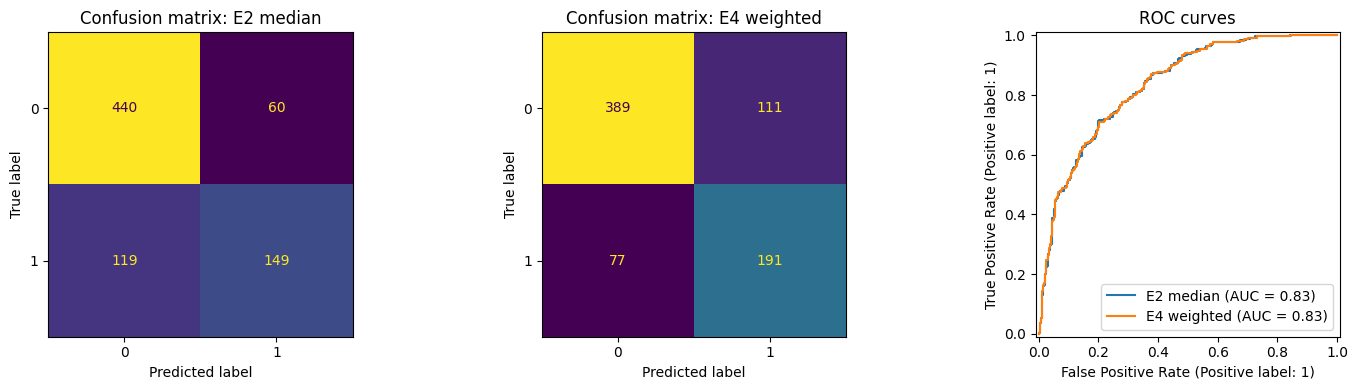

Glucose                     3.11
BMI                         1.89
Pregnancies                 1.51
DiabetesPedigreeFunction    1.33
Age                         1.17
SkinThickness               1.04
Insulin                     0.91
BloodPressure               0.90
dtype: float64


In [15]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pipe) in zip(axes[:2], [("E2 median", pipeline_median), ("E4 weighted", pipeline_weighted)]):
    proba = cross_val_predict(pipe, X, y, cv=cv, method="predict_proba")[:, 1]
    ConfusionMatrixDisplay.from_predictions(y, (proba >= 0.5).astype(int), ax=ax, colorbar=False)
    ax.set_title(f"Confusion matrix: {name}")
    RocCurveDisplay.from_predictions(y, proba, ax=axes[2], name=name)

axes[2].set_title("ROC curves")
plt.tight_layout()
plt.savefig("fig_confusion_roc.png", dpi=300, bbox_inches="tight")
plt.show()

print(odds.sort_values(ascending=False).round(2))

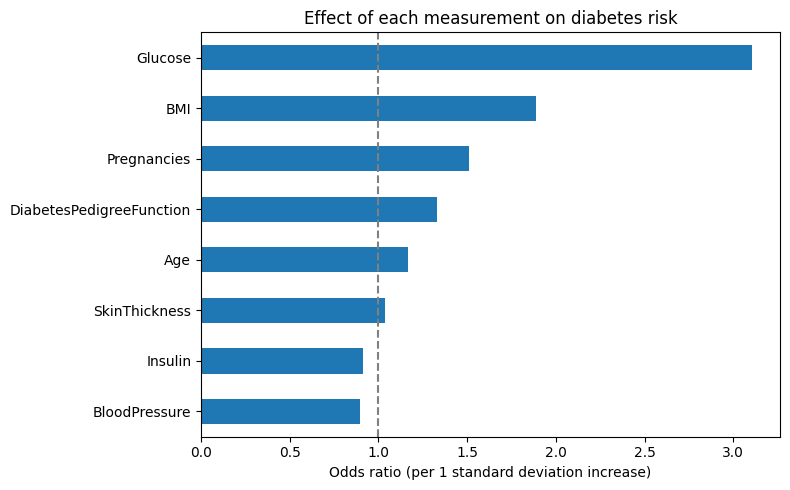

In [14]:
pipeline_median.fit(X, y)
coefs = pipeline_median.named_steps["logreg"].coef_[0]
odds = pd.Series(np.exp(coefs), index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
odds.plot(kind="barh")
plt.axvline(1, color="gray", linestyle="--")
plt.xlabel("Odds ratio (per 1 standard deviation increase)")
plt.title("Effect of each measurement on diabetes risk")
plt.tight_layout()
plt.savefig("fig_odds_ratios.png", dpi=300, bbox_inches="tight")
plt.show()

Class weighting catches significantly more diabetic patients than plain logistic regression.